
# Week 10 Lab — Machine Learning & Dashboards

**Student Name:** Prosper Nishimwe  
**Student ID:** 28926  
**Course:** Introduction to Big Data Analytics  
**Assignment:** Machine Learning & Dashboards

## Objective
This notebook explores student performance data, builds machine learning models to predict examination scores and pass/fail outcomes, evaluates model performance, and creates interactive dashboards.


In [1]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    accuracy_score,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!



# Part 1: Explore and Split

In this section, we load the student dataset, explore the relationships between student performance indicators and examination scores, and divide the data into training and testing sets.


In [2]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())


Current notebook folder:
C:\Users\USER\Desktop\week10

Files in this folder:
['.ipynb_checkpoints', 'class_dashboard.html', 'Lab 5.pdf', 'part5.png', 'part5b.png', 'part5c.png', 'Screenshot 2026-11-10 203304.png', 'Screenshot 2026-11-10 205037.png', 'Screenshot 2026-11-10 205132.png', 'Screenshot 2026-11-10 205206.png', 'Screenshot 2026-11-10 205402.png', 'Screenshot 2026-11-10 205440.png', 'Screenshot 2026-11-10 205525.png', 'Screenshot 2026-11-10 205921.png', 'Screenshot 2026-11-10 210001.png', 'Screenshot 2026-11-10 210053.png', 'Screenshot 2026-11-10 210135.png', 'Screenshot 2026-11-10 210351.png', 'Week10_Prosper_Nishimwe.ipynb', 'week10_students.xlsx']


In [3]:
df = pd.read_excel("week10_students.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (150, 9)


,student_id,name,gender,program,district,attendance_pct,quiz_avg,assignments_avg,score
0,AUCA001,Aline Uwase,F,Information Systems,Gasabo,55,31.0,35.0,28.6
1,AUCA002,Eric Iradukunda,M,Software Engineering,Musanze,73,61.1,76.7,64.5
2,AUCA003,Diane Uwizeyimana,F,Networking,Muhanga,92,35.2,65.5,52.7
3,AUCA004,Jean Bosco Ikirezi,M,Accounting,Kicukiro,69,65.2,54.2,68.3
4,AUCA005,Patrick Ingabire,M,Information Systems,Huye,88,39.3,42.9,42.3


In [4]:
print("Dataset shape:", df.shape)

print("\nCorrelation with examination score:")
print("Quiz average:", df["score"].corr(df["quiz_avg"]))
print("Assignments average:", df["score"].corr(df["assignments_avg"]))
print("Attendance:", df["score"].corr(df["attendance_pct"]))

Dataset shape: (150, 9)

Correlation with examination score:
Quiz average: 0.8007262108513974
Assignments average: 0.5359830904994728
Attendance: 0.23811757632601227


In [5]:
X = df[["quiz_avg", "assignments_avg", "attendance_pct"]]
y = df["score"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 112
Testing rows: 38


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

print("Regression coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

print("Intercept:", model.intercept_)

Regression coefficients:
quiz_avg : 0.5789795370381001
assignments_avg : 0.3647749977025585
attendance_pct : 0.11339589781215703
Intercept: -4.4282133361542435


In [7]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R-squared:", r2)

Mean Absolute Error: 3.3291993077316513
R-squared: 0.886648735661214


In [8]:
new_student = pd.DataFrame({
    "quiz_avg": [70],
    "assignments_avg": [75],
    "attendance_pct": [90]
})

prediction = model.predict(new_student)

print("Predicted examination score:", prediction[0])

Predicted examination score: 73.66410988729879


In [9]:
my_student = pd.DataFrame({
    "quiz_avg": [75],
    "assignments_avg": [80],
    "attendance_pct": [90]
})

my_prediction = model.predict(my_student)

print("My predicted examination score:", my_prediction[0])

My predicted examination score: 78.38288256100208


In [10]:
df["passed"] = (df["score"] >= 50).astype(int)

print("Pass/fail counts:")
print(df["passed"].value_counts())

Pass/fail counts:
passed
1    131
0     19
Name: count, dtype: int64


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

Xc = df[["quiz_avg", "assignments_avg", "attendance_pct"]]
yc = df["passed"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=42
)

classifier = LogisticRegression(max_iter=1000)
classifier.fit(Xc_train, yc_train)

predictions = classifier.predict(Xc_test)

accuracy = accuracy_score(yc_test, predictions)
baseline = yc_test.mean()
cm = confusion_matrix(yc_test, predictions)

print("Model accuracy:", accuracy)
print("Baseline accuracy:", baseline)
print("Confusion matrix:")
print(cm)

Model accuracy: 0.8947368421052632
Baseline accuracy: 0.8947368421052632
Confusion matrix:
[[ 3  1]
 [ 3 31]]


Part 4: Feature Engineering

In [12]:
# Model 1: Quiz average only
X1 = df[["quiz_avg"]]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.25, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)
r2_model1 = r2_score(y1_test, model1.predict(X1_test))


# Model 2: Three numeric features
X2 = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
r2_model2 = r2_score(y2_test, model2.predict(X2_test))


# Model 3: Numeric features plus program
X3 = pd.get_dummies(
    df[["quiz_avg", "assignments_avg", "attendance_pct", "program"]],
    columns=["program"],
    dtype=int
)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.25, random_state=42
)

model3 = LinearRegression()
model3.fit(X3_train, y3_train)
r2_model3 = r2_score(y3_test, model3.predict(X3_test))


comparison = pd.DataFrame({
    "Model": [
        "Quiz only",
        "Three numeric features",
        "Three numeric features + program"
    ],
    "R2 Score": [r2_model1, r2_model2, r2_model3]
})

print(comparison)

                              Model  R2 Score
0                         Quiz only  0.624162
1            Three numeric features  0.886649
2  Three numeric features + program  0.880435


Part 5 — Dashboard

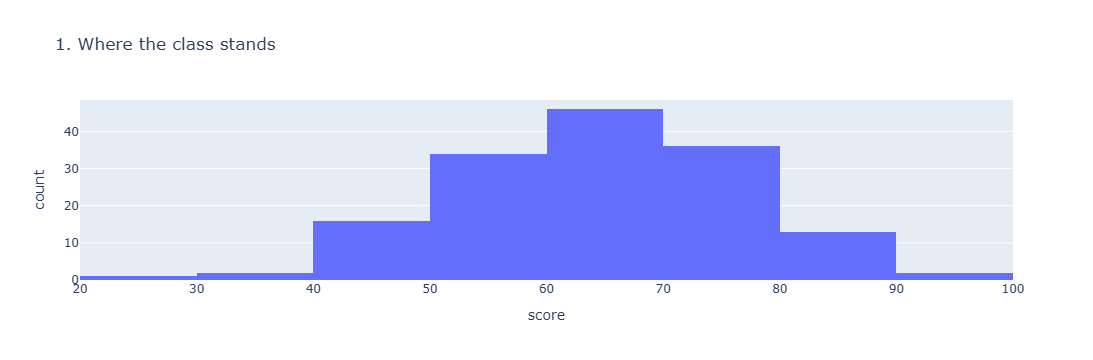

In [13]:
# 1. Histogram: Where the class stands
fig1 = px.histogram(
    df,
    x="score",
    nbins=12,
    title="1. Where the class stands"
)
fig1.show()

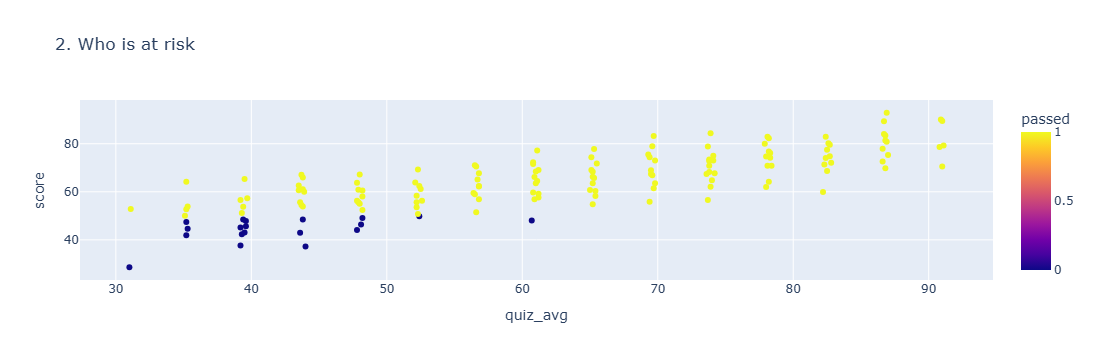

In [14]:
# 2. Scatter plot: Who is at risk
fig2 = px.scatter(
    df,
    x="quiz_avg",
    y="score",
    color="passed",
    hover_name="name",
    title="2. Who is at risk"
)
fig2.show()

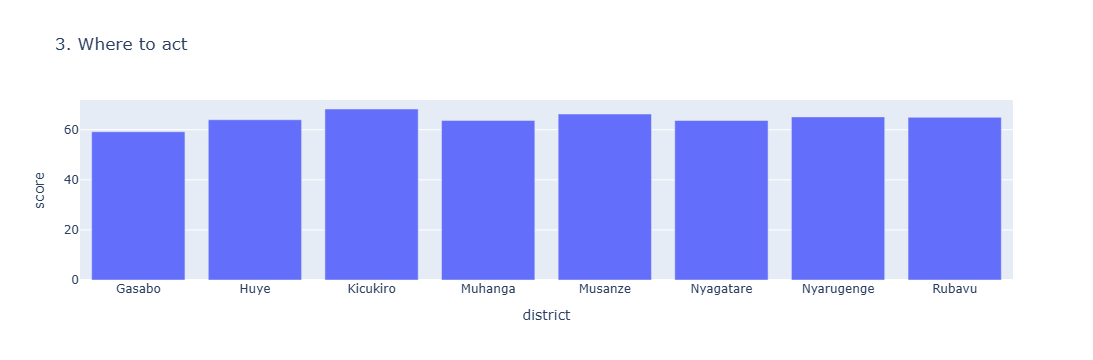

In [15]:
# 3. Average score by district
district_avg = df.groupby("district")["score"].mean().reset_index()

fig3 = px.bar(
    district_avg,
    x="district",
    y="score",
    title="3. Where to act"
)
fig3.show()

In [16]:
fig2.write_html("class_dashboard.html")
print("Dashboard exported successfully!")

Dashboard exported successfully!


## Bonus: Score Distribution by Program

This boxplot compares examination score distributions across different academic programs. It helps identify differences in performance, consistency, and score variation.

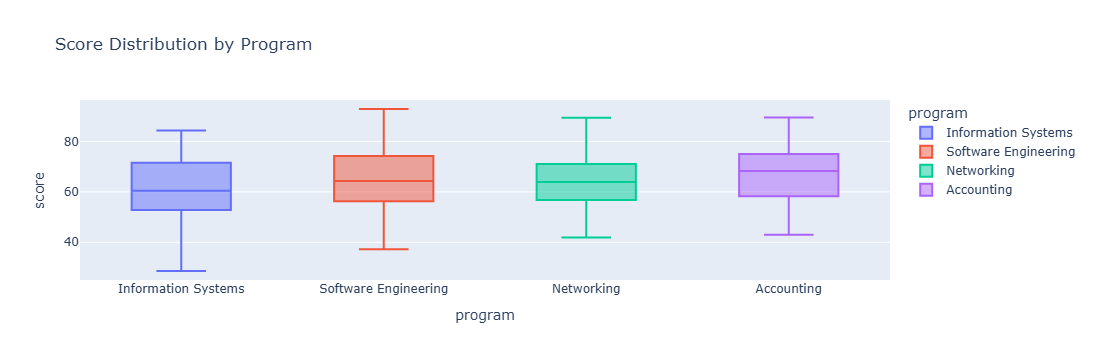

In [17]:
fig4 = px.box(
    df,
    x="program",
    y="score",
    color="program",
    title="Score Distribution by Program"
)

fig4.show()

In [18]:
program_stats = df.groupby("program")["score"].agg(
    ["mean", "std", "min", "max"]
)

program_stats["range"] = program_stats["max"] - program_stats["min"]

print(program_stats.sort_values("std"))

                           mean        std   min   max  range
program                                                      
Networking            64.402703  10.838729  41.9  89.4   47.5
Accounting            66.662162  11.047231  43.0  89.5   46.5
Information Systems   61.589474  12.262727  28.6  84.4   55.8
Software Engineering  64.978947  13.822742  37.2  92.9   55.7


# Model Card: Student Examination Performance Prediction

## 1. Purpose
The model predicts students' examination scores using their quiz averages, assignment averages, and attendance percentages.

## 2. Data and Features
The dataset contains 150 student records.

The model uses:
- Quiz average
- Assignments average
- Attendance percentage

The target variable is the examination score.

## 3. Model Performance
The model uses Linear Regression.

- Mean Absolute Error (MAE): [Insert your actual MAE]
- R-squared (R²): [Insert your actual R²]

The MAE represents the average prediction error in examination-score points. R² indicates how much variation in examination scores the model explains.

## 4. Risks and Limitations
The model may produce inaccurate predictions because student performance can be affected by factors not included in the dataset. The dataset may also contain patterns that do not represent every student fairly.

## 5. Responsible Use
The model should support educational analysis and early identification of students who may need assistance. It should not be used as the only basis for grading, promotion, or disciplinary decisions.

In [20]:
import os

print(os.listdir())
print("MAE:", mae)
print("R²:", r2)

['.ipynb_checkpoints', 'class_dashboard.html', 'Lab 5.pdf', 'part5.png', 'part5b.png', 'part5c.png', 'Screenshot 2026-11-10 203304.png', 'Screenshot 2026-11-10 205037.png', 'Screenshot 2026-11-10 205132.png', 'Screenshot 2026-11-10 205206.png', 'Screenshot 2026-11-10 205402.png', 'Screenshot 2026-11-10 205440.png', 'Screenshot 2026-11-10 205525.png', 'Screenshot 2026-11-10 205921.png', 'Screenshot 2026-11-10 210001.png', 'Screenshot 2026-11-10 210053.png', 'Screenshot 2026-11-10 210135.png', 'Screenshot 2026-11-10 210351.png', 'Week10_Prosper_Nishimwe.ipynb', 'week10_students.xlsx']
MAE: 3.3291993077316513
R²: 0.886648735661214
